In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("Wholesale customers data.csv")
print(df.shape)
df.head()

(440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

x = df.loc[:, features].values
x = StandardScaler().fit_transform(x)

print(x.shape)

(440, 6)


In [ ]:
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(x)
principalDf = pd.DataFrame(data=principalComponents, columns=['principal comp 1', 'principal comp 2'])

finalDf = pd.concat([principalDf, df[['Channel']]], axis=1)
finalDf.head()

,principal comp 1,principal comp 2,Channel
0,0.193291,-0.305100,2
1,0.434420,-0.328413,2
2,0.811143,0.815096,2
3,-0.778648,0.652754,1
4,0.166287,1.271434,2


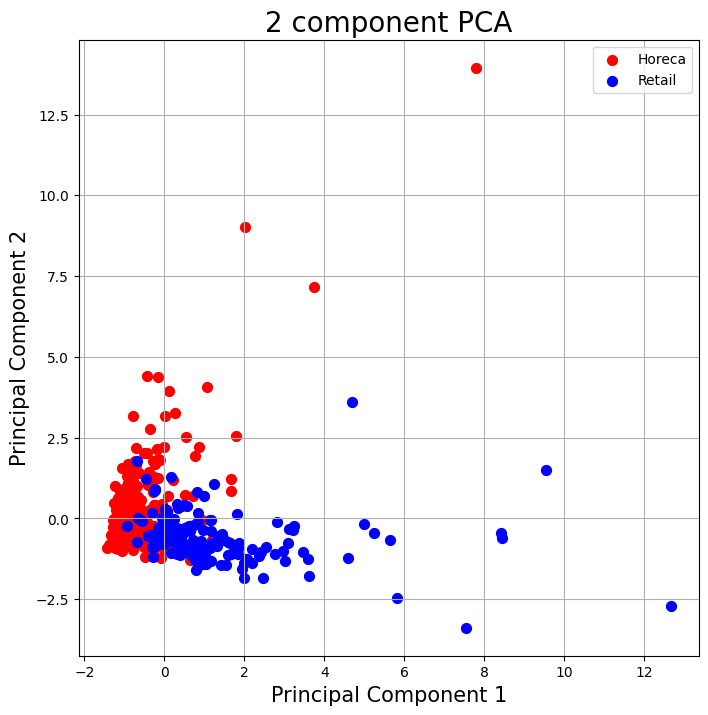

In [ ]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlabel('Principal Component 1', fontsize=15)
ax.set_ylabel('Principal Component 2', fontsize=15)
ax.set_title('2 component PCA', fontsize=20)

targets = [1, 2]
colors = ['r', 'b']
for target, color in zip(targets, colors):
    indicesToKeep = finalDf['Channel'] == target
    ax.scatter(finalDf.loc[indicesToKeep, 'principal comp 1'],
               finalDf.loc[indicesToKeep, 'principal comp 2'],
               c=color,
               s=50)
ax.legend(['Horeca', 'Retail'])
ax.grid()

In [ ]:
pca.explained_variance_ratio_

array([0.44082893, 0.283764  ])

## Summary

This project uses data from 440 customers of a wholesale distributor. The data shows how much each customer spends on 6 kinds of products.

PCA changed the 6 columns into 2 columns. The 2 columns keep 72% of the information.

In the plot, the two types of customers are partly separated. Horeca customers are mostly on the left, and Retail customers are more to the right.

Two columns are enough to see this pattern.

Dataset Source

UCI Machine Learning Repository – Wholesale Customers Dataset

https://archive.ics.uci.edu/dataset/292/wholesale+customers